# C2 PP1 Technical Evidence Pack

This notebook packages the verified Component 2 prototype results into concise PP1-ready evidence.

## Includes
- Function 1 usefulness-model evidence
- Function 2 selector baseline comparison
- Ablation evidence
- Review-budget sensitivity
- Statistical evidence
- Progress / remaining-work summary
- Claim-boundary notes
- Presentation-ready figures

## Important limitation
Current C1 aspect/sentiment data is synthetic integration-test data. Therefore aspect coverage, supported-minority recall, priority-minority coverage and opinion-fidelity values are prototype diagnostics, not final research findings.


In [16]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
print("PP1 evidence-pack environment ready")


PP1 evidence-pack environment ready


## 1. Resolve paths and validate inputs


In [17]:
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "component_2").exists():
    COMPONENT_ROOT = CURRENT_DIR / "component_2"
elif CURRENT_DIR.name == "component_2":
    COMPONENT_ROOT = CURRENT_DIR
elif CURRENT_DIR.name == "notebooks" and CURRENT_DIR.parent.name == "component_2":
    COMPONENT_ROOT = CURRENT_DIR.parent
else:
    raise RuntimeError(f"Could not locate component_2 from: {CURRENT_DIR}")

USEFULNESS_DIR = COMPONENT_ROOT / "results" / "usefulness"
SELECTOR_EVAL_DIR = COMPONENT_ROOT / "results" / "selector_evaluation"
STAT_DIR = COMPONENT_ROOT / "results" / "statistical_validation"
PP1_DIR = COMPONENT_ROOT / "results" / "pp1_evidence"
FIGURE_DIR = PP1_DIR / "figures"
PP1_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TEST_METRICS_PATH = USEFULNESS_DIR / "test_metrics.json"
TEST_BASELINE_PATH = USEFULNESS_DIR / "test_baseline_comparison.csv"
VALIDATION_MODEL_PATH = USEFULNESS_DIR / "validation_model_comparison.csv"
BASELINE_OVERALL_PATH = SELECTOR_EVAL_DIR / "baseline_comparison_overall.csv"
ABLATION_OVERALL_PATH = SELECTOR_EVAL_DIR / "ablation_overall.csv"
BUDGET_OVERALL_PATH = SELECTOR_EVAL_DIR / "budget_sensitivity_overall.csv"
PP1_MAIN_STATS_PATH = STAT_DIR / "pp1_main_evidence.csv"
PP1_ABLATION_STATS_PATH = STAT_DIR / "pp1_ablation_evidence.csv"

required = {
    "test_metrics": TEST_METRICS_PATH,
    "test_baseline": TEST_BASELINE_PATH,
    "validation_models": VALIDATION_MODEL_PATH,
    "baseline_overall": BASELINE_OVERALL_PATH,
    "ablation_overall": ABLATION_OVERALL_PATH,
    "budget_overall": BUDGET_OVERALL_PATH,
    "pp1_main_stats": PP1_MAIN_STATS_PATH,
    "pp1_ablation_stats": PP1_ABLATION_STATS_PATH,
}
print("Component root:", COMPONENT_ROOT)
for name, path in required.items():
    print(f"{name}: {path.exists()} -> {path}")

missing = [str(p) for p in required.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing PP1 evidence artifacts:\\n" + "\\n".join(missing)
    )
print("\\nAll required PP1 evidence artifacts found.")


Component root: d:\Research\Repository\J26-DS-349\component_2
test_metrics: True -> d:\Research\Repository\J26-DS-349\component_2\results\usefulness\test_metrics.json
test_baseline: True -> d:\Research\Repository\J26-DS-349\component_2\results\usefulness\test_baseline_comparison.csv
validation_models: True -> d:\Research\Repository\J26-DS-349\component_2\results\usefulness\validation_model_comparison.csv
baseline_overall: True -> d:\Research\Repository\J26-DS-349\component_2\results\selector_evaluation\baseline_comparison_overall.csv
ablation_overall: True -> d:\Research\Repository\J26-DS-349\component_2\results\selector_evaluation\ablation_overall.csv
budget_overall: True -> d:\Research\Repository\J26-DS-349\component_2\results\selector_evaluation\budget_sensitivity_overall.csv
pp1_main_stats: True -> d:\Research\Repository\J26-DS-349\component_2\results\statistical_validation\pp1_main_evidence.csv
pp1_ablation_stats: True -> d:\Research\Repository\J26-DS-349\component_2\results\stati

## 2. Load verified outputs


In [18]:
with open(TEST_METRICS_PATH,"r",encoding="utf-8") as f: test_metrics_json=json.load(f)
test_baseline_df=pd.read_csv(TEST_BASELINE_PATH)
validation_models_df=pd.read_csv(VALIDATION_MODEL_PATH)
baseline_overall_df=pd.read_csv(BASELINE_OVERALL_PATH)
ablation_overall_df=pd.read_csv(ABLATION_OVERALL_PATH)
budget_overall_df=pd.read_csv(BUDGET_OVERALL_PATH)
pp1_main_stats_df=pd.read_csv(PP1_MAIN_STATS_PATH)
pp1_ablation_stats_df=pd.read_csv(PP1_ABLATION_STATS_PATH)

print("Function 1 baseline rows:",len(test_baseline_df))
print("Validation model rows:",len(validation_models_df))
print("Selector methods:",len(baseline_overall_df))
print("Ablation variants:",len(ablation_overall_df))
print("Budget settings:",len(budget_overall_df))
print("PP1 main-stat rows:",len(pp1_main_stats_df))
print("PP1 ablation-stat rows:",len(pp1_ablation_stats_df))

assert {"FullProposed","PredictedUsefulnessTopK","HelpfulnessMMR","AspectCoverage","ProposedNoMinority"}.issubset(set(baseline_overall_df["selector"]))
assert {"FullProposed","NoMinority","NoCoverage","NoRedundancy","NoRepresentativeness"}.issubset(set(ablation_overall_df["selector"]))
assert set(budget_overall_df["budget_k"])=={3,5,7,10}
print("PP1 evidence-source validation passed.")


Function 1 baseline rows: 2
Validation model rows: 3
Selector methods: 6
Ablation variants: 5
Budget settings: 4
PP1 main-stat rows: 6
PP1 ablation-stat rows: 5
PP1 evidence-source validation passed.


## 3. Function 1 evidence


In [19]:
print("Held-out test metrics:")
display(pd.DataFrame([test_metrics_json]))
print("\\nTest baseline comparison:")
display(test_baseline_df)
print("\\nValidation model comparison:")
display(validation_models_df)


Held-out test metrics:


,model,alpha,MAE,RMSE,Spearman,Spearman_p,NDCG@5,NDCG@10
0,TFIDF_Ridge,10.0,0.563167,0.665546,0.309733,0.00023,0.588248,0.651073


\nTest baseline comparison:


,model,alpha,MAE,RMSE,Spearman,Spearman_p,NDCG@5,NDCG@10
0,DummyMean,NaN,0.594834,0.706376,NaN,NaN,NaN,NaN
1,TFIDF_Ridge,10.0,0.563167,0.665546,0.309733,0.00023,0.588248,0.651073


\nValidation model comparison:


,model,alpha,MAE,RMSE,Spearman,Spearman_p,NDCG@5,NDCG@10
0,TFIDF_Ridge,0.1,0.582310,0.710793,0.349126,3.558321e-05,0.592585,0.698966
1,TFIDF_Ridge,1.0,0.536713,0.661993,0.383967,4.651768e-06,0.656855,0.744745
2,TFIDF_Ridge,10.0,0.543328,0.672643,0.410755,8.238698e-07,0.706220,0.764598


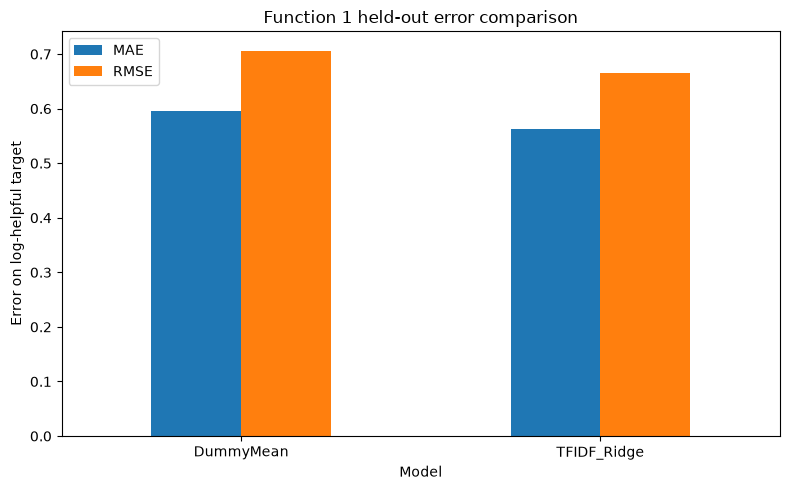

Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\figures\01_function1_error_comparison.png


In [20]:
def norm_col(x): return str(x).strip().lower().replace(" ","_").replace("-","_")
def pick_col(df,candidates):
    for c in candidates:
        if c in df.columns: return c
    return None

tmp=test_baseline_df.copy(); tmp.columns=[norm_col(c) for c in tmp.columns]
model_col=pick_col(tmp,["model","method","baseline"])
mae_col=pick_col(tmp,["mae","test_mae"])
rmse_col=pick_col(tmp,["rmse","test_rmse"])
FUNCTION1_ERROR_FIG=FIGURE_DIR/"01_function1_error_comparison.png"

if model_col and mae_col and rmse_col:
    function1_error_df=tmp[[model_col,mae_col,rmse_col]].rename(columns={model_col:"model",mae_col:"MAE",rmse_col:"RMSE"})
    ax=function1_error_df.set_index("model")[["MAE","RMSE"]].plot(kind="bar",figsize=(8,5))
    ax.set_title("Function 1 held-out error comparison"); ax.set_xlabel("Model"); ax.set_ylabel("Error on log-helpful target"); ax.tick_params(axis="x",rotation=0)
    plt.tight_layout(); plt.savefig(FUNCTION1_ERROR_FIG,dpi=200,bbox_inches="tight"); plt.show(); print("Saved:",FUNCTION1_ERROR_FIG)
else:
    function1_error_df=pd.DataFrame(); print("Function 1 error chart skipped; available columns:",list(tmp.columns))


## 4. Function 2 selector comparison


In [21]:
selector_cols=["selector","mean_usefulness_norm","mean_representativeness_norm","mean_aspect_coverage","mean_supported_minority_recall","mean_priority_minority_coverage","mean_pairwise_similarity","mean_opinion_js_divergence"]
function2_comparison_df=baseline_overall_df[selector_cols].copy()
display(function2_comparison_df)


,selector,mean_usefulness_norm,mean_representativeness_norm,mean_aspect_coverage,mean_supported_minority_recall,mean_priority_minority_coverage,mean_pairwise_similarity,mean_opinion_js_divergence
0,AspectCoverage,0.851174,0.712649,1.000000,0.306072,0.15,0.475217,0.277468
1,FullProposed,0.742725,0.766597,0.933333,0.416744,1.00,0.492611,0.336771
2,HelpfulnessMMR,0.850566,0.691175,0.800000,0.293057,0.10,0.438294,0.332131
3,ObservedHelpfulTopK,0.768678,0.681043,0.866667,0.322098,0.20,0.411797,0.314594
4,PredictedUsefulnessTopK,0.859078,0.711964,0.816667,0.278294,0.10,0.472905,0.316286
5,ProposedNoMinority,0.834591,0.772256,0.966667,0.281072,0.20,0.510038,0.296061


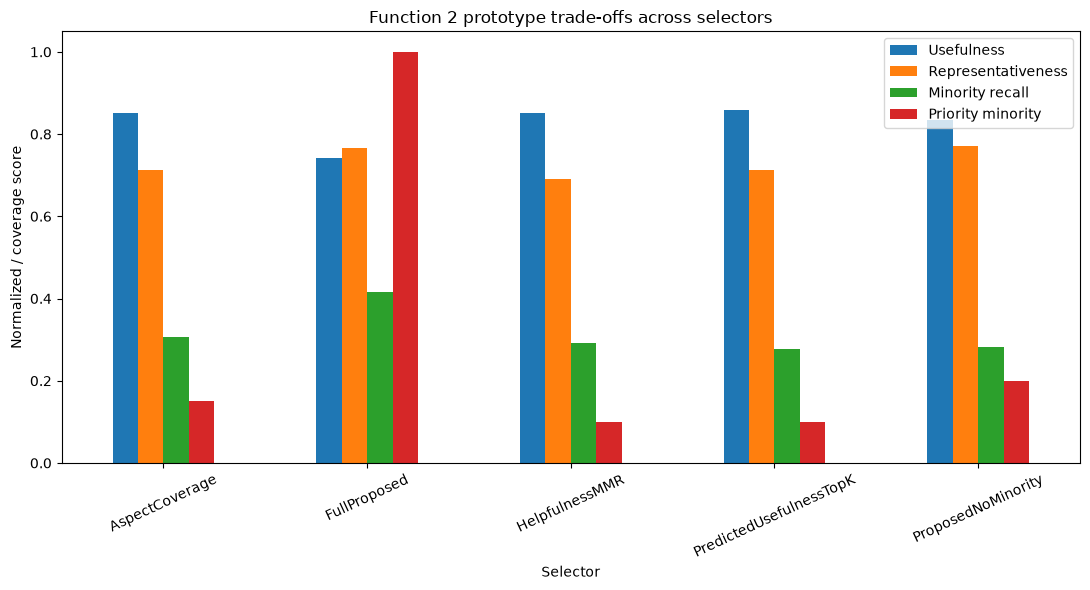

Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\figures\02_selector_key_metrics.png


In [22]:
SELECTOR_KEY_FIG=FIGURE_DIR/"02_selector_key_metrics.png"
methods=["FullProposed","PredictedUsefulnessTopK","HelpfulnessMMR","AspectCoverage","ProposedNoMinority"]
plot_df=(function2_comparison_df[function2_comparison_df["selector"].isin(methods)].set_index("selector")[["mean_usefulness_norm","mean_representativeness_norm","mean_supported_minority_recall","mean_priority_minority_coverage"]].rename(columns={"mean_usefulness_norm":"Usefulness","mean_representativeness_norm":"Representativeness","mean_supported_minority_recall":"Minority recall","mean_priority_minority_coverage":"Priority minority"}))
ax=plot_df.plot(kind="bar",figsize=(11,6)); ax.set_title("Function 2 prototype trade-offs across selectors"); ax.set_xlabel("Selector"); ax.set_ylabel("Normalized / coverage score"); ax.set_ylim(0,1.05); ax.tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.savefig(SELECTOR_KEY_FIG,dpi=200,bbox_inches="tight"); plt.show(); print("Saved:",SELECTOR_KEY_FIG)


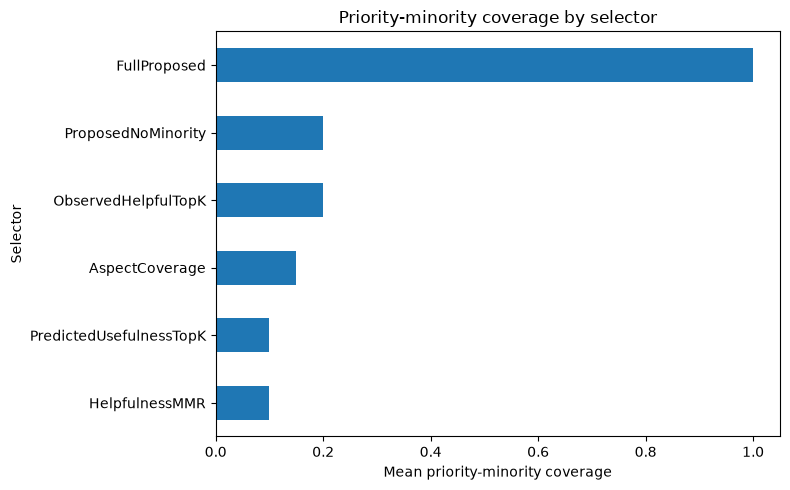

Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\figures\03_priority_minority_coverage.png


In [23]:
PRIORITY_FIG=FIGURE_DIR/"03_priority_minority_coverage.png"
priority_df=function2_comparison_df[["selector","mean_priority_minority_coverage"]].sort_values("mean_priority_minority_coverage")
ax=priority_df.plot(kind="barh",x="selector",y="mean_priority_minority_coverage",legend=False,figsize=(8,5)); ax.set_title("Priority-minority coverage by selector"); ax.set_xlabel("Mean priority-minority coverage"); ax.set_ylabel("Selector"); ax.set_xlim(0,1.05)
plt.tight_layout(); plt.savefig(PRIORITY_FIG,dpi=200,bbox_inches="tight"); plt.show(); print("Saved:",PRIORITY_FIG)


## 5. Ablation evidence


,selector,mean_usefulness_norm,mean_representativeness_norm,mean_observed_log_helpful,mean_aspect_coverage,mean_supported_minority_recall,mean_priority_minority_coverage,mean_pairwise_similarity,mean_opinion_js_divergence
0,FullProposed,0.742725,0.766597,1.824493,0.933333,0.416744,1.0,0.492611,0.336771
1,NoCoverage,0.750342,0.772539,1.989514,0.833333,0.408411,1.0,0.501894,0.383803
2,NoMinority,0.834591,0.772256,2.199952,0.966667,0.281072,0.2,0.510038,0.296061
3,NoRedundancy,0.728990,0.792706,1.869119,0.950000,0.442855,1.0,0.514537,0.331134
4,NoRepresentativeness,0.736532,0.647577,1.810330,0.933333,0.398376,1.0,0.377265,0.334438


,selector_b,metric_label,mean_a,mean_b,mean_benefit_difference,benefit_ci_95_low,benefit_ci_95_high,wilcoxon_p,holm_p
0,NoMinority,Supported-minority recall,0.416744,0.281072,0.135672,0.082168,0.195125,0.003906,0.011719
1,NoMinority,Priority-minority coverage,1.000000,0.200000,0.800000,0.650000,0.950000,0.001953,0.009766
2,NoCoverage,Aspect coverage,0.933333,0.833333,0.100000,0.016667,0.183333,0.125000,0.218750
3,NoRedundancy,Pairwise similarity,0.492611,0.514537,0.021926,0.000693,0.051679,0.109375,0.218750
4,NoRepresentativeness,Semantic representativeness,0.766597,0.647577,0.119019,0.081538,0.154691,0.001953,0.009766


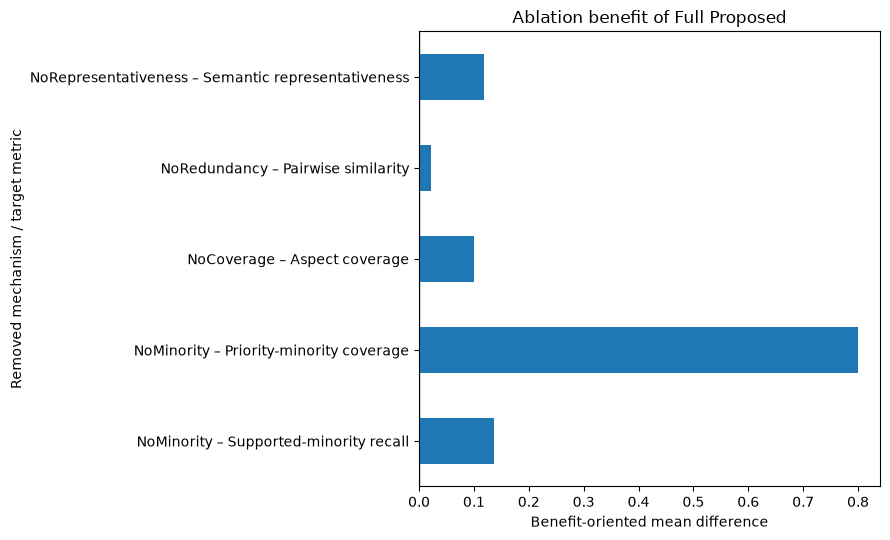

Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\figures\04_ablation_benefit_differences.png


In [24]:
display(ablation_overall_df)
display(pp1_ablation_stats_df)
ABLATION_FIG=FIGURE_DIR/"04_ablation_benefit_differences.png"
ablation_plot_df=pp1_ablation_stats_df[["selector_b","metric_label","mean_benefit_difference"]].copy()
ablation_plot_df["comparison"]=ablation_plot_df["selector_b"].astype(str)+" – "+ablation_plot_df["metric_label"].astype(str)
ax=ablation_plot_df.plot(kind="barh",x="comparison",y="mean_benefit_difference",legend=False,figsize=(9,5.5)); ax.set_title("Ablation benefit of Full Proposed"); ax.set_xlabel("Benefit-oriented mean difference"); ax.set_ylabel("Removed mechanism / target metric"); ax.axvline(0,linewidth=1)
plt.tight_layout(); plt.savefig(ABLATION_FIG,dpi=200,bbox_inches="tight"); plt.show(); print("Saved:",ABLATION_FIG)


## 6. Review-budget sensitivity


,budget_k,mean_usefulness_norm,mean_representativeness_norm,mean_aspect_coverage,mean_supported_minority_recall,mean_priority_minority_coverage,mean_pairwise_similarity,mean_opinion_js_divergence
0,3,0.671043,0.783232,0.716667,0.327183,1.0,0.477134,0.522149
1,5,0.742725,0.766597,0.933333,0.416744,1.0,0.492611,0.336771
2,7,0.738860,0.779718,0.983333,0.482148,1.0,0.503333,0.264055
3,10,0.717390,0.775821,1.000000,0.677615,1.0,0.497510,0.158290


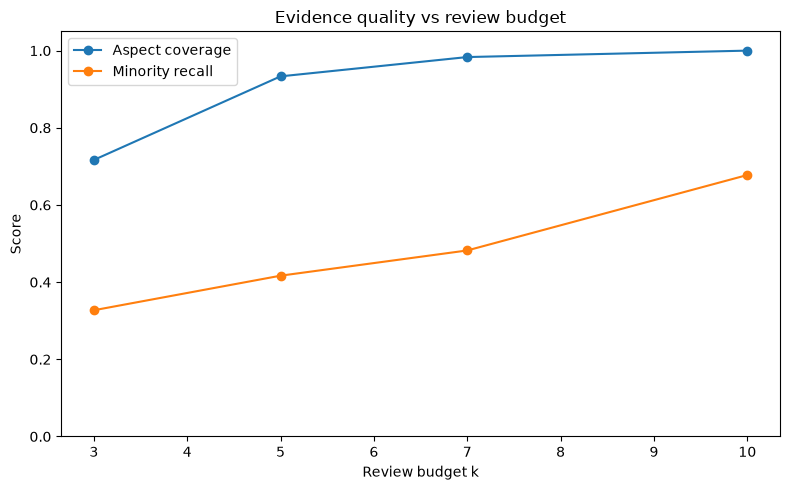

Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\figures\05_budget_sensitivity.png


In [25]:
display(budget_overall_df)
BUDGET_FIG=FIGURE_DIR/"05_budget_sensitivity.png"
budget_plot_df=(budget_overall_df[["budget_k","mean_aspect_coverage","mean_supported_minority_recall"]].sort_values("budget_k").set_index("budget_k").rename(columns={"mean_aspect_coverage":"Aspect coverage","mean_supported_minority_recall":"Minority recall"}))
ax=budget_plot_df.plot(kind="line",marker="o",figsize=(8,5)); ax.set_title("Evidence quality vs review budget"); ax.set_xlabel("Review budget k"); ax.set_ylabel("Score"); ax.set_ylim(0,1.05)
plt.tight_layout(); plt.savefig(BUDGET_FIG,dpi=200,bbox_inches="tight"); plt.show(); print("Saved:",BUDGET_FIG)


## 7. Statistical evidence


In [26]:
display(pp1_main_stats_df)
display(pp1_ablation_stats_df)
statistical_summary_df=pp1_ablation_stats_df[["selector_b","metric_label","mean_a","mean_b","mean_benefit_difference","benefit_ci_95_low","benefit_ci_95_high","holm_p"]].copy()
statistical_summary_df["holm_significant_0_05"]=statistical_summary_df["holm_p"]<0.05
display(statistical_summary_df)


,selector_b,metric_label,mean_a,mean_b,mean_benefit_difference,benefit_ci_95_low,benefit_ci_95_high,wilcoxon_p,holm_p
0,PredictedUsefulnessTopK,Predicted usefulness,0.742725,0.859078,-0.116353,-0.152127,-0.079277,0.001953,0.078125
1,PredictedUsefulnessTopK,Supported-minority recall,0.416744,0.278294,0.138450,0.074475,0.208803,0.007812,0.203125
2,PredictedUsefulnessTopK,Priority-minority coverage,1.000000,0.100000,0.900000,0.750000,1.000000,0.001953,0.078125
3,HelpfulnessMMR,Pairwise similarity,0.492611,0.438294,-0.054316,-0.109153,-0.001513,0.160156,1.000000
4,ProposedNoMinority,Supported-minority recall,0.416744,0.281072,0.135672,0.082051,0.195470,0.003906,0.117188
5,ProposedNoMinority,Priority-minority coverage,1.000000,0.200000,0.800000,0.650000,0.950000,0.001953,0.078125


,selector_b,metric_label,mean_a,mean_b,mean_benefit_difference,benefit_ci_95_low,benefit_ci_95_high,wilcoxon_p,holm_p
0,NoMinority,Supported-minority recall,0.416744,0.281072,0.135672,0.082168,0.195125,0.003906,0.011719
1,NoMinority,Priority-minority coverage,1.000000,0.200000,0.800000,0.650000,0.950000,0.001953,0.009766
2,NoCoverage,Aspect coverage,0.933333,0.833333,0.100000,0.016667,0.183333,0.125000,0.218750
3,NoRedundancy,Pairwise similarity,0.492611,0.514537,0.021926,0.000693,0.051679,0.109375,0.218750
4,NoRepresentativeness,Semantic representativeness,0.766597,0.647577,0.119019,0.081538,0.154691,0.001953,0.009766


,selector_b,metric_label,mean_a,mean_b,mean_benefit_difference,benefit_ci_95_low,benefit_ci_95_high,holm_p,holm_significant_0_05
0,NoMinority,Supported-minority recall,0.416744,0.281072,0.135672,0.082168,0.195125,0.011719,True
1,NoMinority,Priority-minority coverage,1.000000,0.200000,0.800000,0.650000,0.950000,0.009766,True
2,NoCoverage,Aspect coverage,0.933333,0.833333,0.100000,0.016667,0.183333,0.218750,False
3,NoRedundancy,Pairwise similarity,0.492611,0.514537,0.021926,0.000693,0.051679,0.218750,False
4,NoRepresentativeness,Semantic representativeness,0.766597,0.647577,0.119019,0.081538,0.154691,0.009766,True


## 8. Progress and claim boundaries


In [27]:
progress_status_df=pd.DataFrame([
["Smartphone pilot data preparation and EDA","Completed","896 cleaned reviews across 10 products","Real-data implementation evidence"],
["Function 1 usefulness model","Completed – preliminary model","TF-IDF + Ridge; chronological split; held-out metrics and inference tests","Real-data held-out prototype evidence"],
["Semantic representation","Completed","Sentence-BERT embeddings for 896 reviews","Real-review representation evidence"],
["C1 input integration","Prototype integration completed","Validated stable review-ID joins and provisional contract","Synthetic C1 integration test only"],
["Supported-minority qualification","Prototype completed","Support, prevalence and confidence qualification pipeline","Synthetic C1 diagnostic only"],
["Function 2 constrained selector","Completed – first prototype","Fixed budget: 5 reviews × 10 products","Mixed real-review + synthetic-C1 evidence"],
["Baseline / ablation / sensitivity evaluation","Completed – pilot","Six selectors; ablations; budget and weight sensitivity","Prototype evaluation evidence"],
["Statistical validation","Completed – exploratory pilot","Wilcoxon, bootstrap CI and Holm correction across 10 products","Exploratory prototype evidence"],
["Real C1 replacement","Pending","Final real C1 output not yet available","Remaining work"],
["Broader smartphone + laptop evaluation","Pending","Current implementation uses smartphone pilot only","Remaining work"],
["Final model / threshold / weight validation","Pending","Current settings are preliminary","Remaining work"],
],columns=["work_package","status","evidence","claim_type"])
display(progress_status_df)

claim_boundary_df=pd.DataFrame([
["Function 1 held-out metrics","Preliminary held-out usefulness-model results on the real smartphone pilot.","Final usefulness model performance."],
["Minority recall / priority coverage","Prototype diagnostics show that the explicit minority mechanism preserves more supported minority evidence.","Final research proves minority preservation on real C1 outputs."],
["Ablation significance","Exploratory product-level evidence supports the minority and representativeness mechanisms.","The method is statistically superior overall."],
["Baseline comparison","The selector shows an intended multi-objective trade-off rather than maximizing usefulness alone.","The proposed method is best on every metric."],
["Current C1 integration","The C1→C2 software contract is tested using clearly labelled synthetic fixtures.","Real C1 integration is complete."],
],columns=["evidence_area","safe_pp1_wording","avoid_wording"])
display(claim_boundary_df)


,work_package,status,evidence,claim_type
0,Smartphone pilot data preparation and EDA,Completed,896 cleaned reviews across 10 products,Real-data implementation evidence
1,Function 1 usefulness model,Completed – preliminary model,TF-IDF + Ridge; chronological split; held-out ...,Real-data held-out prototype evidence
2,Semantic representation,Completed,Sentence-BERT embeddings for 896 reviews,Real-review representation evidence
3,C1 input integration,Prototype integration completed,Validated stable review-ID joins and provision...,Synthetic C1 integration test only
4,Supported-minority qualification,Prototype completed,"Support, prevalence and confidence qualificati...",Synthetic C1 diagnostic only
5,Function 2 constrained selector,Completed – first prototype,Fixed budget: 5 reviews × 10 products,Mixed real-review + synthetic-C1 evidence
6,Baseline / ablation / sensitivity evaluation,Completed – pilot,Six selectors; ablations; budget and weight se...,Prototype evaluation evidence
7,Statistical validation,Completed – exploratory pilot,"Wilcoxon, bootstrap CI and Holm correction acr...",Exploratory prototype evidence
8,Real C1 replacement,Pending,Final real C1 output not yet available,Remaining work
9,Broader smartphone + laptop evaluation,Pending,Current implementation uses smartphone pilot only,Remaining work


,evidence_area,safe_pp1_wording,avoid_wording
0,Function 1 held-out metrics,Preliminary held-out usefulness-model results ...,Final usefulness model performance.
1,Minority recall / priority coverage,Prototype diagnostics show that the explicit m...,Final research proves minority preservation on...
2,Ablation significance,Exploratory product-level evidence supports th...,The method is statistically superior overall.
3,Baseline comparison,The selector shows an intended multi-objective...,The proposed method is best on every metric.
4,Current C1 integration,The C1→C2 software contract is tested using cl...,Real C1 integration is complete.


## 9. Compact PP1 selector summary


In [28]:
full_row=baseline_overall_df[baseline_overall_df["selector"]=="FullProposed"].iloc[0]
pred_row=baseline_overall_df[baseline_overall_df["selector"]=="PredictedUsefulnessTopK"].iloc[0]
no_minority_row=baseline_overall_df[baseline_overall_df["selector"]=="ProposedNoMinority"].iloc[0]

pp1_selector_summary_df=pd.DataFrame([
{"comparison":"Full vs Predicted Usefulness Top-K","usefulness":f"{full_row['mean_usefulness_norm']:.3f} vs {pred_row['mean_usefulness_norm']:.3f}","representativeness":f"{full_row['mean_representativeness_norm']:.3f} vs {pred_row['mean_representativeness_norm']:.3f}","minority_recall":f"{full_row['mean_supported_minority_recall']:.3f} vs {pred_row['mean_supported_minority_recall']:.3f}","priority_minority":f"{full_row['mean_priority_minority_coverage']:.2f} vs {pred_row['mean_priority_minority_coverage']:.2f}","interpretation":"Trades usefulness for stronger representativeness and minority preservation."},
{"comparison":"Full vs Proposed without Minority","usefulness":f"{full_row['mean_usefulness_norm']:.3f} vs {no_minority_row['mean_usefulness_norm']:.3f}","representativeness":f"{full_row['mean_representativeness_norm']:.3f} vs {no_minority_row['mean_representativeness_norm']:.3f}","minority_recall":f"{full_row['mean_supported_minority_recall']:.3f} vs {no_minority_row['mean_supported_minority_recall']:.3f}","priority_minority":f"{full_row['mean_priority_minority_coverage']:.2f} vs {no_minority_row['mean_priority_minority_coverage']:.2f}","interpretation":"Explicit minority preservation materially changes the selected evidence set."},
])
display(pp1_selector_summary_df)


,comparison,usefulness,representativeness,minority_recall,priority_minority,interpretation
0,Full vs Predicted Usefulness Top-K,0.743 vs 0.859,0.767 vs 0.712,0.417 vs 0.278,1.00 vs 0.10,Trades usefulness for stronger representativen...
1,Full vs Proposed without Minority,0.743 vs 0.835,0.767 vs 0.772,0.417 vs 0.281,1.00 vs 0.20,Explicit minority preservation materially chan...


## 10. Save PP1 evidence pack


In [29]:
FUNCTION1_TABLE_PATH=PP1_DIR/"function1_test_baseline_comparison.csv"
FUNCTION2_TABLE_PATH=PP1_DIR/"function2_selector_comparison.csv"
ABLATION_TABLE_PATH=PP1_DIR/"ablation_summary.csv"
BUDGET_TABLE_PATH=PP1_DIR/"budget_sensitivity_summary.csv"
STAT_TABLE_PATH=PP1_DIR/"statistical_summary.csv"
PROGRESS_PATH=PP1_DIR/"progress_status.csv"
CLAIM_BOUNDARY_PATH=PP1_DIR/"claim_boundaries.csv"
SELECTOR_SUMMARY_PATH=PP1_DIR/"pp1_selector_summary.csv"
SUMMARY_MD_PATH=PP1_DIR/"component2_pp1_evidence_summary.md"
MANIFEST_PATH=PP1_DIR/"evidence_manifest.json"

test_baseline_df.to_csv(FUNCTION1_TABLE_PATH,index=False)
function2_comparison_df.to_csv(FUNCTION2_TABLE_PATH,index=False)
pp1_ablation_stats_df.to_csv(ABLATION_TABLE_PATH,index=False)
budget_overall_df.to_csv(BUDGET_TABLE_PATH,index=False)
statistical_summary_df.to_csv(STAT_TABLE_PATH,index=False)
progress_status_df.to_csv(PROGRESS_PATH,index=False)
claim_boundary_df.to_csv(CLAIM_BOUNDARY_PATH,index=False)
pp1_selector_summary_df.to_csv(SELECTOR_SUMMARY_PATH,index=False)

significant=statistical_summary_df[statistical_summary_df["holm_significant_0_05"]]
summary_lines=[
"# Component 2 – PP1 Evidence Summary","","## Current implementation",
"- Smartphone pilot: 896 cleaned reviews across 10 products.",
"- Function 1: preliminary TF-IDF + Ridge usefulness model with held-out evaluation.",
"- Semantic representation: Sentence-BERT embeddings for all 896 pilot reviews.",
"- Function 2: fixed-budget constrained selector selecting 5 reviews per product.",
"- Baseline, ablation, sensitivity and exploratory statistical validation completed.","",
"## Prototype selector evidence",
f"- Full Proposed mean usefulness: {full_row['mean_usefulness_norm']:.3f}; Predicted-Usefulness Top-K: {pred_row['mean_usefulness_norm']:.3f}.",
f"- Full Proposed supported-minority recall: {full_row['mean_supported_minority_recall']:.3f}; Predicted-Usefulness Top-K: {pred_row['mean_supported_minority_recall']:.3f}.",
f"- Full Proposed priority-minority coverage: {full_row['mean_priority_minority_coverage']:.2f}; Proposed without Minority: {no_minority_row['mean_priority_minority_coverage']:.2f}.","","## Statistically supported prototype ablations"]
for _,row in significant.iterrows():
    summary_lines.append(
        f"- Full Proposed vs {row['selector_b']} on {row['metric_label']}: benefit {row['mean_benefit_difference']:.3f}, 95% CI [{row['benefit_ci_95_low']:.3f}, {row['benefit_ci_95_high']:.3f}], Holm p={row['holm_p']:.4f}."
    )
summary_lines += ["","## Claim boundary","- C1-derived aspect/sentiment labels are synthetic integration-test placeholders.","- Minority, coverage and opinion-fidelity values are prototype diagnostics, not final research findings.","- Statistical tests are exploratory because the current pilot contains only 10 products.","- Real C1 integration, broader category evaluation and final model/parameter validation remain future work."]
SUMMARY_MD_PATH.write_text("\n".join(summary_lines),encoding="utf-8")

manifest={
    "tables":[str(p.relative_to(COMPONENT_ROOT)) for p in [FUNCTION1_TABLE_PATH,FUNCTION2_TABLE_PATH,ABLATION_TABLE_PATH,BUDGET_TABLE_PATH,STAT_TABLE_PATH,PROGRESS_PATH,CLAIM_BOUNDARY_PATH,SELECTOR_SUMMARY_PATH]],
    "figures":[str(p.relative_to(COMPONENT_ROOT)) for p in sorted(FIGURE_DIR.glob("*.png"))],
    "summary":str(SUMMARY_MD_PATH.relative_to(COMPONENT_ROOT)),
    "limitation":"C1-derived evidence currently uses synthetic integration-test data."
}
with open(MANIFEST_PATH,"w",encoding="utf-8") as f:
    json.dump(manifest,f,indent=2)
for p in [FUNCTION1_TABLE_PATH,FUNCTION2_TABLE_PATH,ABLATION_TABLE_PATH,BUDGET_TABLE_PATH,STAT_TABLE_PATH,PROGRESS_PATH,CLAIM_BOUNDARY_PATH,SELECTOR_SUMMARY_PATH,SUMMARY_MD_PATH,MANIFEST_PATH]:
    print("Saved:",p)
print("Figures saved:",len(list(FIGURE_DIR.glob("*.png"))))


Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\function1_test_baseline_comparison.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\function2_selector_comparison.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\ablation_summary.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\budget_sensitivity_summary.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\statistical_summary.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\progress_status.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\claim_boundaries.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\pp1_selector_summary.csv
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\component2_pp1_evidence_summary.md
Saved: d:\Research\Repository\J26-DS-349\component_2\results\pp1_evidence\evidence_m

## 11. Final validation


In [30]:
required_outputs=[FUNCTION1_TABLE_PATH,FUNCTION2_TABLE_PATH,ABLATION_TABLE_PATH,BUDGET_TABLE_PATH,STAT_TABLE_PATH,PROGRESS_PATH,CLAIM_BOUNDARY_PATH,SELECTOR_SUMMARY_PATH,SUMMARY_MD_PATH,MANIFEST_PATH,SELECTOR_KEY_FIG,PRIORITY_FIG,ABLATION_FIG,BUDGET_FIG]
if not function1_error_df.empty: required_outputs.append(FUNCTION1_ERROR_FIG)
for p in required_outputs: assert p.exists(), f"Missing PP1 evidence artifact: {p}"
assert len(progress_status_df)>=8
assert len(claim_boundary_df)==claim_boundary_df["evidence_area"].nunique()
assert len(pp1_selector_summary_df)==pp1_selector_summary_df["comparison"].nunique()
print("PP1 technical evidence-pack validation passed.")


PP1 technical evidence-pack validation passed.


## 12. Milestone summary

### Completed
- Function 1 evidence consolidated
- Function 2 comparison packaged
- Ablation evidence packaged
- Budget sensitivity packaged
- Statistical evidence summarized
- Progress / remaining-work table generated
- Claim-boundary table generated
- Presentation-ready figures generated
- Evidence manifest and PP1 summary generated

### Next
Use the evidence pack to prepare the Component 2 PP1 slides, demonstration flow and panel Q&A.
